# Road to Ariadne 0.3

This notebook presents the scientific story and figure order behind Ariadne 0.3:

1. RSA straightening
2. Tip preservation
3. Fixed-spacing versus analytical continuous fronts
4. Random null models and the optimization landscape
5. Sampling-based classification of a real RSA

The notebook is intended for interactive exploration. Adjust the file path and
the sample counts at the top, then execute the cells in order.

## Setup and graph selection

In [1]:
%matplotlib inline

import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from ariadne_roots import config
from ariadne_roots.pareto_functions import (
    get_critical_nodes,
    graph_costs,
    pareto_front,
    point_dist,
)
from ariadne_roots.quantify import estimate_rounds_for_region, get_graph_from_json
from ariadne_roots.research import (
    compare_fixed_spacing_granularity,
    compare_pareto_fronts_multi,
    comparaplot_four_random,
    pareto_steiner_fast_analytical_preserve_tips,
    pareto_steiner_fast_preserve_tips,
    pareto_steiner_fast_preserve_tips_fixed_spacing_binary_pareto,
    plot_randomization_landscape,
    plot_rsa_and_abstraction,
    plot_steiner_sequence_double,
    random_tree,
    random_tree_normalized,
)

# Representative graph used in the notebook.
GRAPH_PATH = Path(
    "tests/data/_set1_day1_20240429-125122_012_plantE_day1.json"
)

# Publication-scale settings. Reduce these for a quick exploratory run.
N_MST = 500
N_TOPDOWN = 200
N_BOTTOMUP = 300
N_ANALYTICAL = 500
N_LANDSCAPE = 500
N_SAMPLES = 5000
REGION_FACTOR = 0.75

config.length_scale_factor = 1.0
config.length_scale_unit = "px"

G = get_graph_from_json(GRAPH_PATH)
H = G.to_undirected()

# The algorithms use edge weights as Euclidean distances.
for u, v in H.edges():
    if "weight" not in H[u][v]:
        H[u][v]["weight"] = point_dist(
            H.nodes[u]["pos"], H.nodes[v]["pos"]
        )

print(f"Loaded: {GRAPH_PATH.name}")
print(f"Nodes: {H.number_of_nodes()}, edges: {H.number_of_edges()}")
print(f"Critical nodes: {len(get_critical_nodes(H))}")

Loaded: _set1_day1_20240429-125122_012_plantE_day1.json
Nodes: 87, edges: 86
Critical nodes: 18


## 1. The digitized RSA and its straightened representation

The digitized graph, while faithful to the original image, contains many intermediate nodes that reflect the resolution of the digitization but this geometry is not being accounted for in the pareto front or the random model generation. For the purposes of optimization and comparison, we work with a *straightened* version of the graph, in which only the root base, the tips, and the branching points (nodes of degree $\geq 3$) are retained. All remaining intermediate nodes are removed, and the retained nodes are connected by straight-line edges whose weights are the Euclidean distances between them. This straightened graph preserves the topology and the key geometric landmarks of the original root system while removing digitization artifacts. It is this straightened representation that serves as the input to all subsequent algorithms, and as the reference point against which optimized architectures are compared (the figure below).

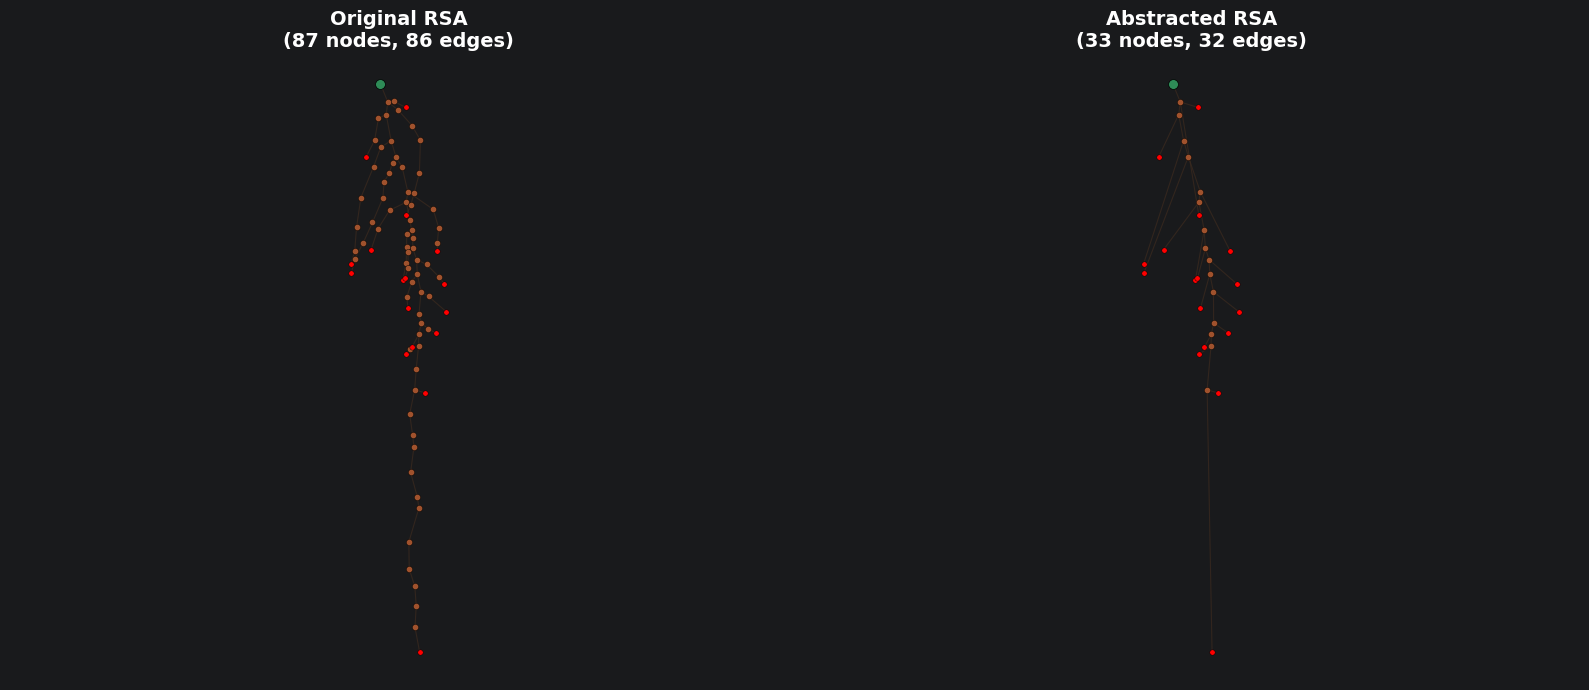

In [2]:
fig, axes = plot_rsa_and_abstraction(H)
plt.show()

## 2. Tip preservation

The original greedy Steiner construction would consume tips as internal branch
points. The tip-preserving construction keeps every original tip terminal.

We therefore developed a tip-preserving variant of the algorithm, in which all original tips remain terminal nodes and branch points are placed only along the connecting segments. The figure below contrasts the two behaviors on a representative root system.

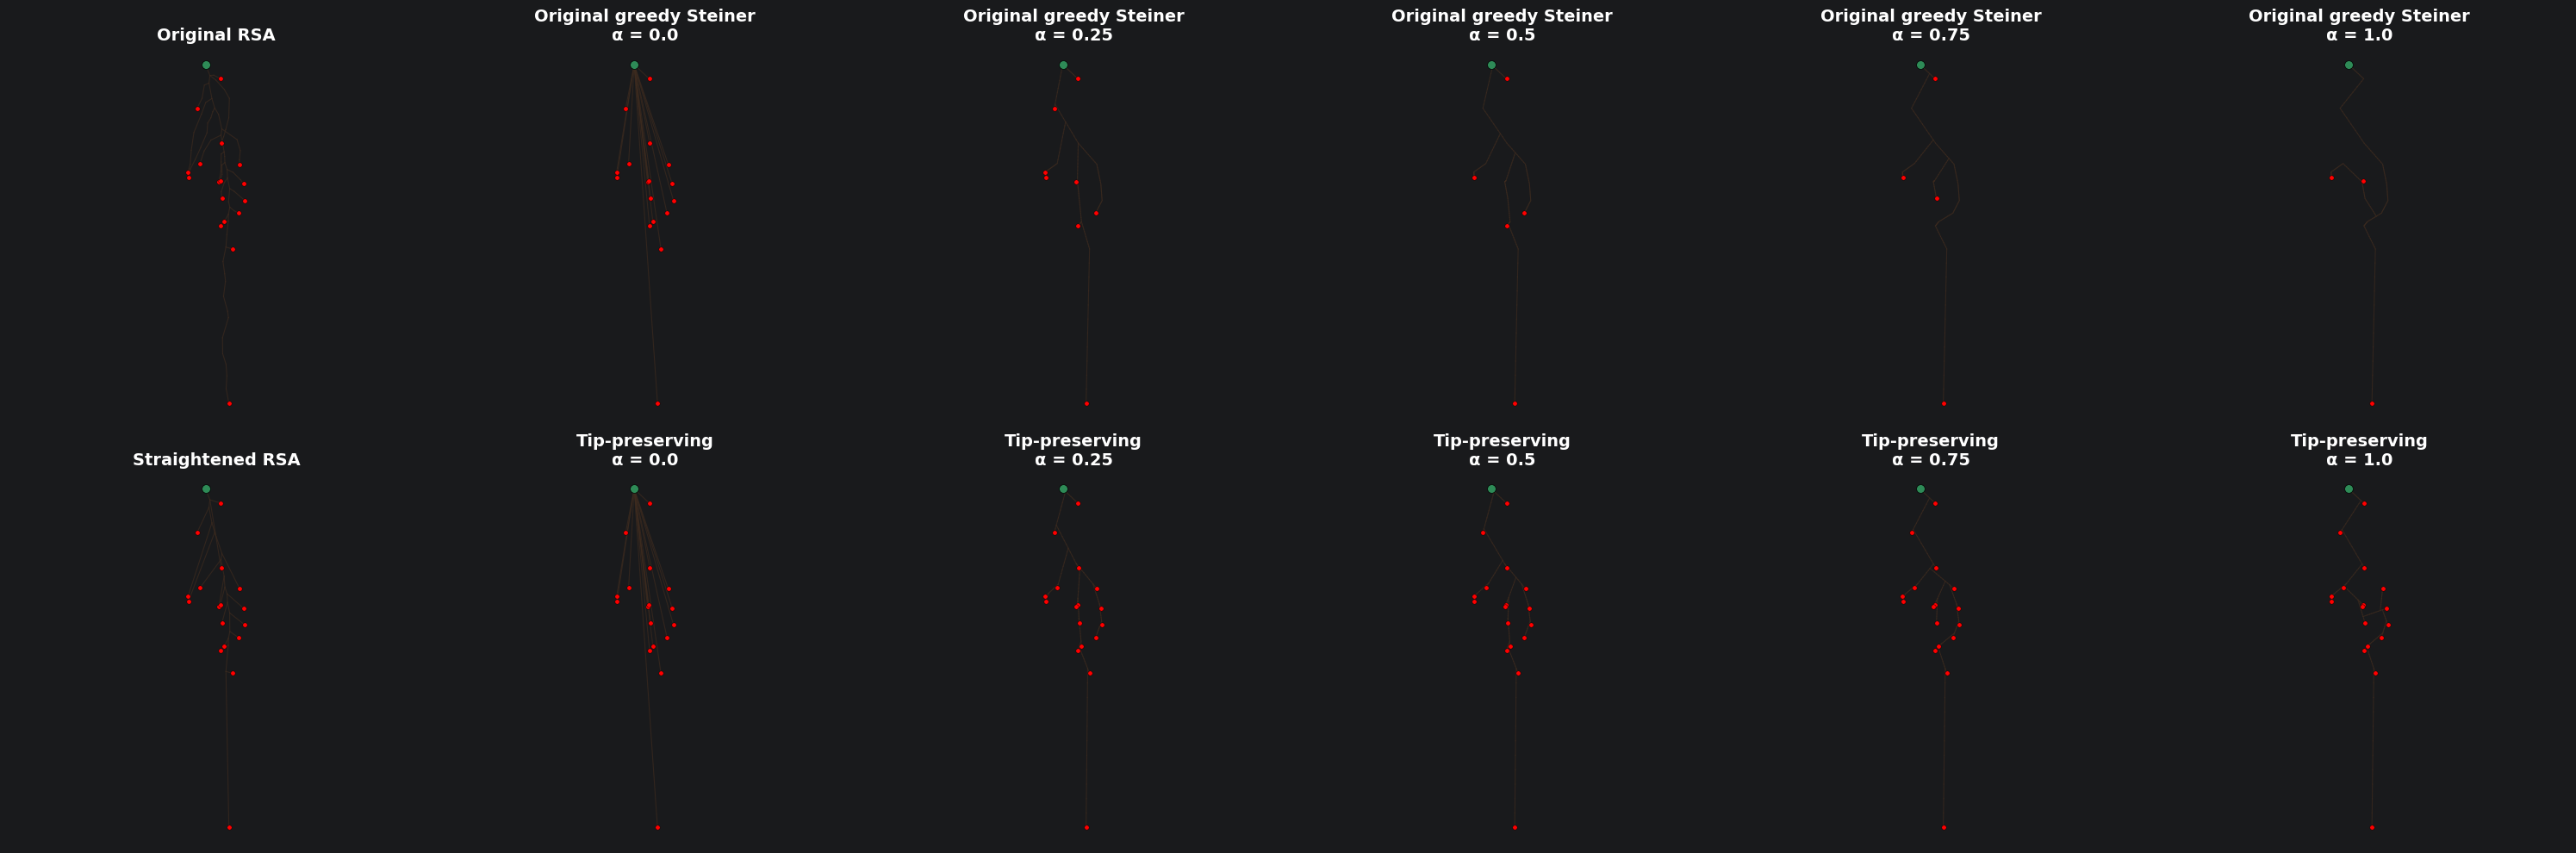

In [3]:
# Import the legacy/original generator under an explicit name.
from ariadne_roots.research import pareto_steiner_fast as original_steiner

fig = plot_steiner_sequence_double(
    H,
    original_steiner,
    pareto_steiner_fast_preserve_tips,
    alphas=[0.0, 0.25, 0.5, 0.75, 1.0],
    label_1="Original greedy Steiner",
    label_2="Tip-preserving",
)
plt.show()

## 3. Fixed-spacing versus analytical continuous fronts

The progression from the original greedy algorithm to the tip-preserving fixed-spacing binary algorithm and finally to the analytical continuous algorithm can thus be seen as a tightening of biological plausibility combined with a gradual increase in computational precision. Each step removes an artificial constraint—first tip consumption, then unbounded branching, then discrete placement—while preserving the core structure of the Pareto optimization framework. The figure below shows the three fronts side by side.

Current front points: 82
Actual straightened tree: (7856.1637430625005, 21751.421516739985)
Processing graph 1/1...
  Tip-preserving greedy...
  Fixed-spacing binary (spacing = 0.5 × min LR length)...
  Analytical continuous...


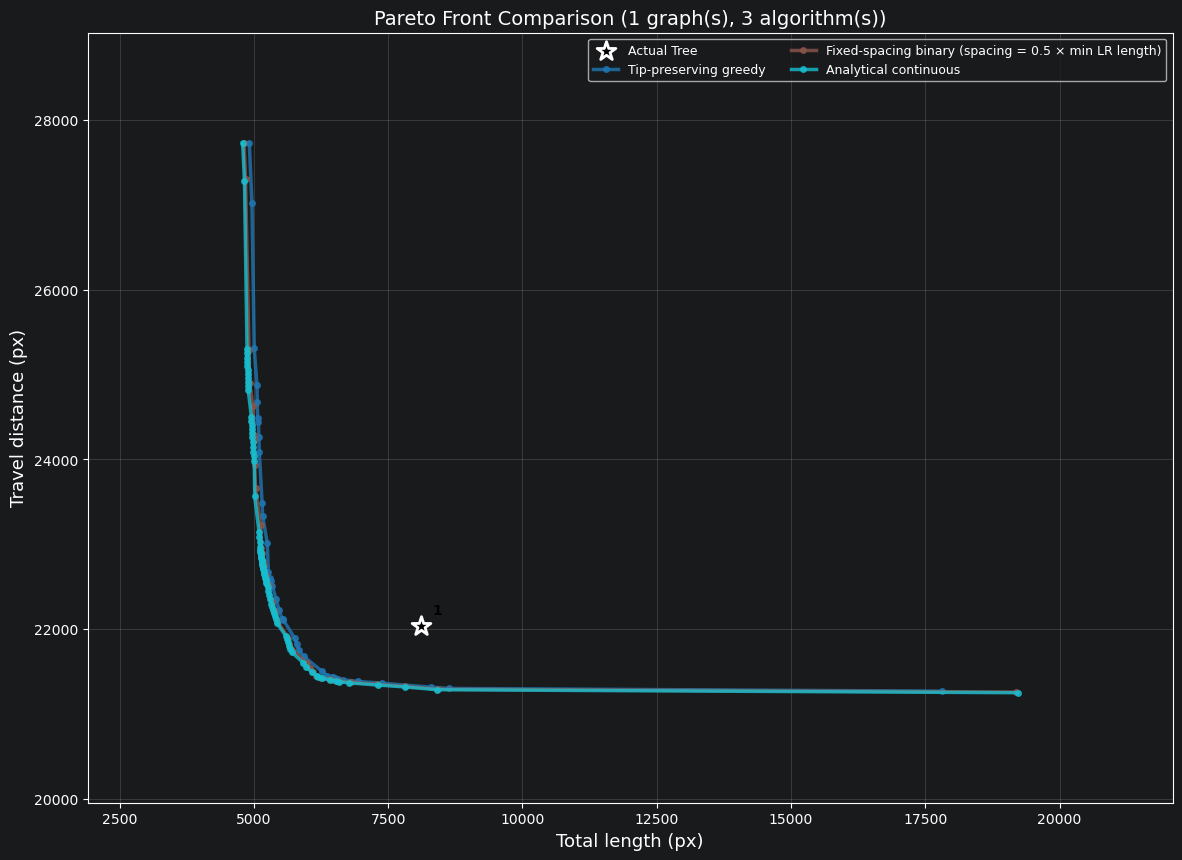

(<Figure size 1400x1000 with 1 Axes>,
 <Axes: title={'center': 'Pareto Front Comparison (1 graph(s), 3 algorithm(s))'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [4]:
front, actual = pareto_front(H)

print(f"Current front points: {len(front)}")
print(f"Actual straightened tree: {actual}")

compare_pareto_fronts_multi(
    H,
    [
        pareto_steiner_fast_preserve_tips,
        pareto_steiner_fast_preserve_tips_fixed_spacing_binary_pareto,
        pareto_steiner_fast_analytical_preserve_tips,
    ],
    labels=[
        "Tip-preserving greedy",
        "Fixed-spacing binary (spacing = 0.5 × min LR length)",
        "Analytical continuous",
    ],
)

The fixed-spacing construction converges toward the analytical continuous
front as its spacing becomes finer.

To validate the coherence of our approach, we examined the relationship between the fixed-spacing and continuous variants of the greedy Steiner algorithm. Since the fixed-spacing algorithm restricts candidate branch points to a discrete grid along each edge, while the continuous algorithm allows attachment anywhere, the two should converge as the grid spacing becomes arbitrarily fine. We tested this by computing Pareto fronts for the fixed-spacing algorithm across a range of spacing factors, from coarse to very fine, and comparing them against the front produced by the analytical continuous algorithm. As expected, the fixed-spacing fronts approach the continuous front from above as the spacing decreases, with the finest grids producing fronts that are nearly indistinguishable from the continuous solution (the figure below). This convergence confirms that the two algorithms are consistent formulations of the same underlying optimization problem. Importantly, however, the computational cost of the fixed-spacing approach grows dramatically as the grid is refined—fronts at very fine spacings require orders of magnitude more time—whereas the analytical continuous algorithm achieves the same or better precision at a fraction of the cost. The analytical solution is therefore not only more accurate but also more efficient, making it the preferable method for large-scale analyses.

Computing continuous Pareto front...
Computing fixed-spacing front (spacing_factor=0.2)...
Computing fixed-spacing front (spacing_factor=0.4)...
Computing fixed-spacing front (spacing_factor=0.6)...
Computing fixed-spacing front (spacing_factor=0.8)...
Computing fixed-spacing front (spacing_factor=1.0)...


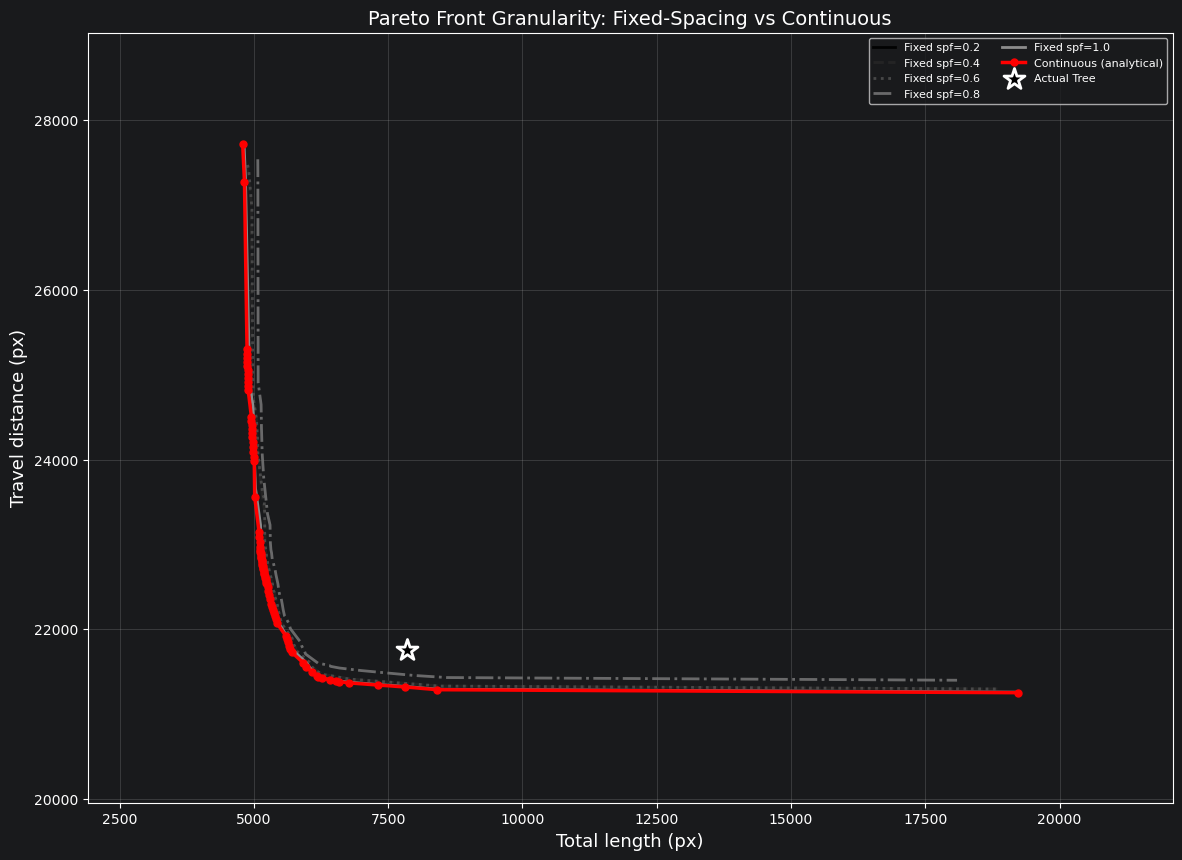

(<Figure size 1400x1000 with 1 Axes>,
 <Axes: title={'center': 'Pareto Front Granularity: Fixed-Spacing vs Continuous'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [5]:
compare_fixed_spacing_granularity(
    H,
    spacing_list=[0.2, 0.4, 0.6, 0.8, 1.0],
    min_length_factor=0.5,
)

## 4. Random null models

The original random spanning-tree null model is corrected by normalizing travel
distance to the number of tips in the generated tree.

The two artifacts thus pulled in opposite directions: the first inflated travel distance by counting internal nodes as if they were tips, while the second deflated it by simply having fewer tips. In practice, the deflationary effect was stronger. In the corrected version of the algorithm, we measure travel distance only to the tips of the generated random tree, and then normalize by the ratio of the original number of tips to the number of tips in the generated RSA. This ensures that random architectures with fewer terminal points are compared on an equal footing with the digitized root. As a result, the normalized random trees exhibit slightly higher travel distances than the uncorrected ones, reflecting the removal of the net deflationary bias. The figure below illustrates the effect of this correction. This adjustment brings the null model into methodological alignment with the rest of the framework, ensuring that all comparisons—whether optimal, random, or empirical—are made under the same set of conventions.

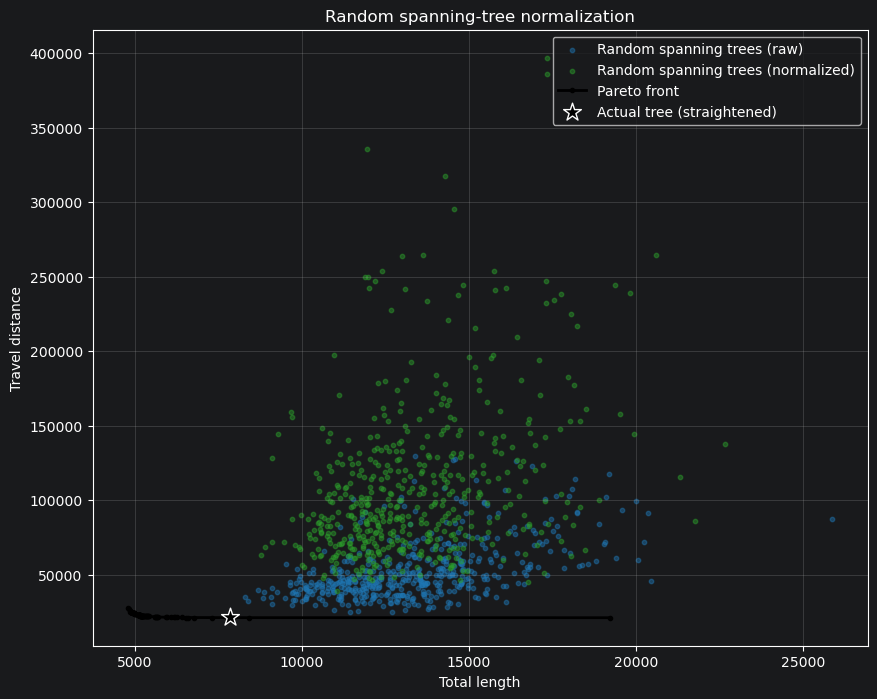

In [6]:
costs_raw, _ = random_tree(H, n=N_MST)
costs_normalized, _ = random_tree_normalized(H, n=N_MST)

front, actual = pareto_front(H)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(
    [c[0] for c in costs_raw],
    [c[1] for c in costs_raw],
    s=10,
    alpha=0.45,
    color="tab:blue",
    label="Random spanning trees (raw)",
)
ax.scatter(
    [c[0] for c in costs_normalized],
    [c[1] for c in costs_normalized],
    s=10,
    alpha=0.45,
    color="tab:green",
    label="Random spanning trees (normalized)",
)
ax.plot(
    [p[0] for p in front.values()],
    [p[1] for p in front.values()],
    color="black",
    linewidth=2,
    marker="o",
    markersize=3,
    label="Pareto front",
)
ax.scatter(
    actual[0],
    actual[1],
    marker="*",
    s=180,
    color="black",
    edgecolors="white",
    zorder=5,
    label="Actual tree (straightened)",
)
ax.set_xlabel("Total length")
ax.set_ylabel("Travel distance")
ax.set_title("Random spanning-tree normalization")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Four constrained random generators: corrected spanning tree, top-down,
bottom-up, and randomized analytical.

The figure below compares the four random generators—the corrected spanning-tree null model, the top-down generator, the bottom-up generator, and the randomized analytical algorithm—on a representative root system. The clouds of points they produce in the Pareto plane differ both in their location and in their spread, illustrating that the choice of null model has a substantial impact on the statistical assessment of root system optimality. The generators that integrate more structural hypotheses (top-down, bottom-up, randomized analytical) tend to produce architectures that lie closer to the Pareto front than the naive spanning tree, reflecting the fact that biological plausibility and transport efficiency are not entirely independent: architectures that respect root-like branching rules tend to be more efficient than arbitrary networks. This underscores the importance of using biologically informed null models when interpreting the position of real root systems relative to optimality.

Generating random spanning trees (normalized)...
  Got 500 trees
Generating top-down trees...
    Base -> 101 (order 0)
    101 (order=0) -> 88 (internal, order=0)
    88 (order=0) -> 89 (internal, order=1)
    88 (order=0) -> 50 (tip, order=1)
    101 (order=0) -> 97 (internal, order=1)
    97 (order=1) -> 44 (tip, order=2)
    97 (order=1) -> 95 (internal, order=1)
    95 (order=1) -> 87 (internal, order=1)
    95 (order=1) -> 42 (tip, order=1)
    87 (order=1) -> 92 (internal, order=1)
    87 (order=1) -> 91 (internal, order=1)
    89 (order=1) -> 69 (tip, order=2)
    89 (order=1) -> 100 (internal, order=1)
    100 (order=1) -> 90 (internal, order=1)
    100 (order=1) -> 99 (internal, order=1)
    91 (order=1) -> 39 (tip, order=1)
    91 (order=1) -> 93 (internal, order=1)
    99 (order=1) -> 65 (tip, order=1)
    99 (order=1) -> 78 (tip, order=1)
    92 (order=1) -> 62 (tip, order=1)
    92 (order=1) -> 94 (internal, order=1)
    93 (order=1) -> 58 (tip, order=1)
    93 (order=1) 

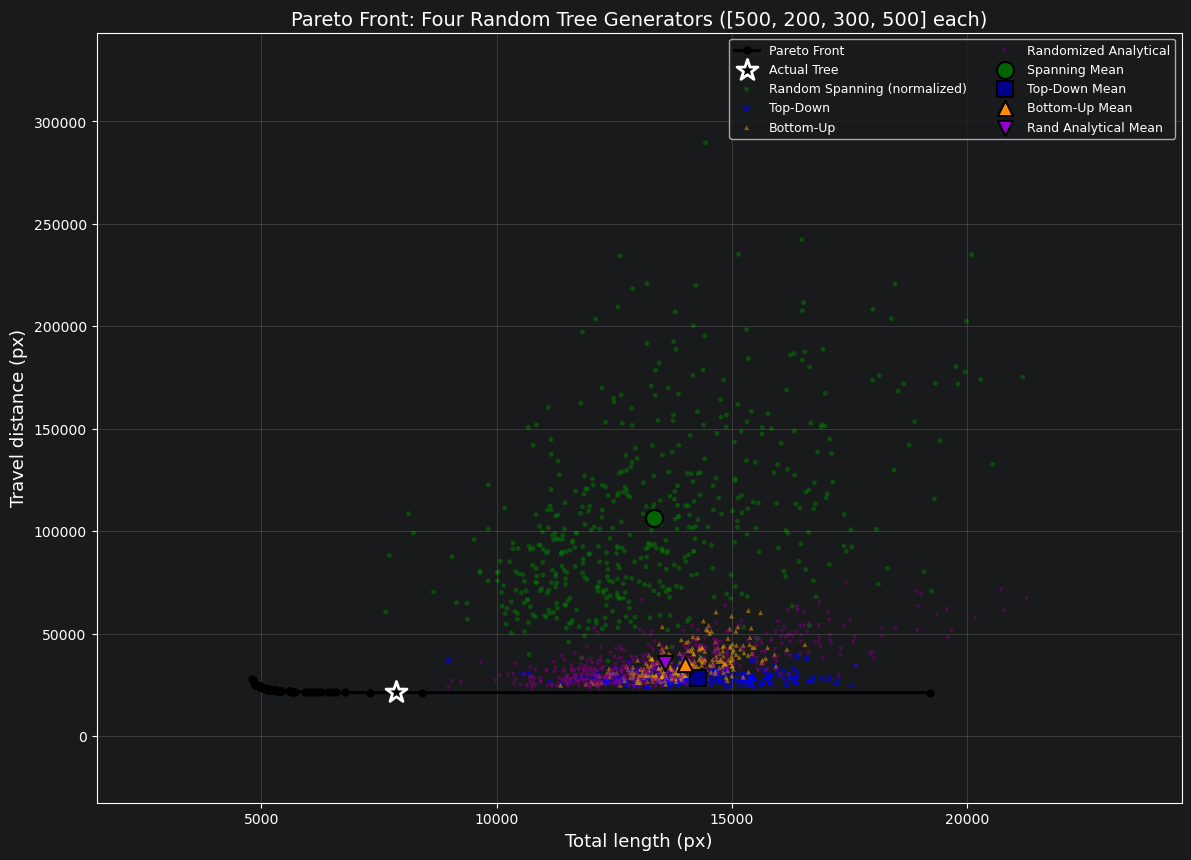

(<Figure size 1400x1000 with 1 Axes>,
 <Axes: title={'center': 'Pareto Front: Four Random Tree Generators ([500, 200, 300, 500] each)'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [7]:
comparaplot_four_random(
    H,
    n_random=[N_MST, N_TOPDOWN, N_BOTTOMUP, N_ANALYTICAL],
    verbose=False,
)

The optimization landscape interpolates between fully greedy and fully random
analytical constructions through the number of optimization rounds.

The figure below visualizes this continuum for a representative root system. Each point corresponds to a single generated tree, with the color indicating the number of optimization rounds (blue for fully optimal, red for fully random) and the point size encoding the trade-off parameter $\alpha$. Fully Pareto-optimal trees appear as blue diamonds clustered along the Pareto front, while fully random trees drift upward and to the right, populating the region of high wiring and high travel costs. The intermediate trees form a bridge between these two extremes, illustrating how progressive relaxation of the optimization pressure pushes architectures away from the front. This landscape provides a rich backdrop against which the position of the actual root system can be interpreted: not merely as a single point relative to the front, but as a location within a graded space of possible architectures.

Generating 500 randomized trees...
Max rounds (fully Pareto): 17
  Generating 100 fully Pareto-optimal trees...
  Generating 100 fully random trees...
  Generating 300 trees with random rounds...
    Generated 50/300
    Generated 100/300
    Generated 150/300
    Generated 200/300
    Generated 250/300
    Generated 300/300
  Total: 500 trees, 100 optimal


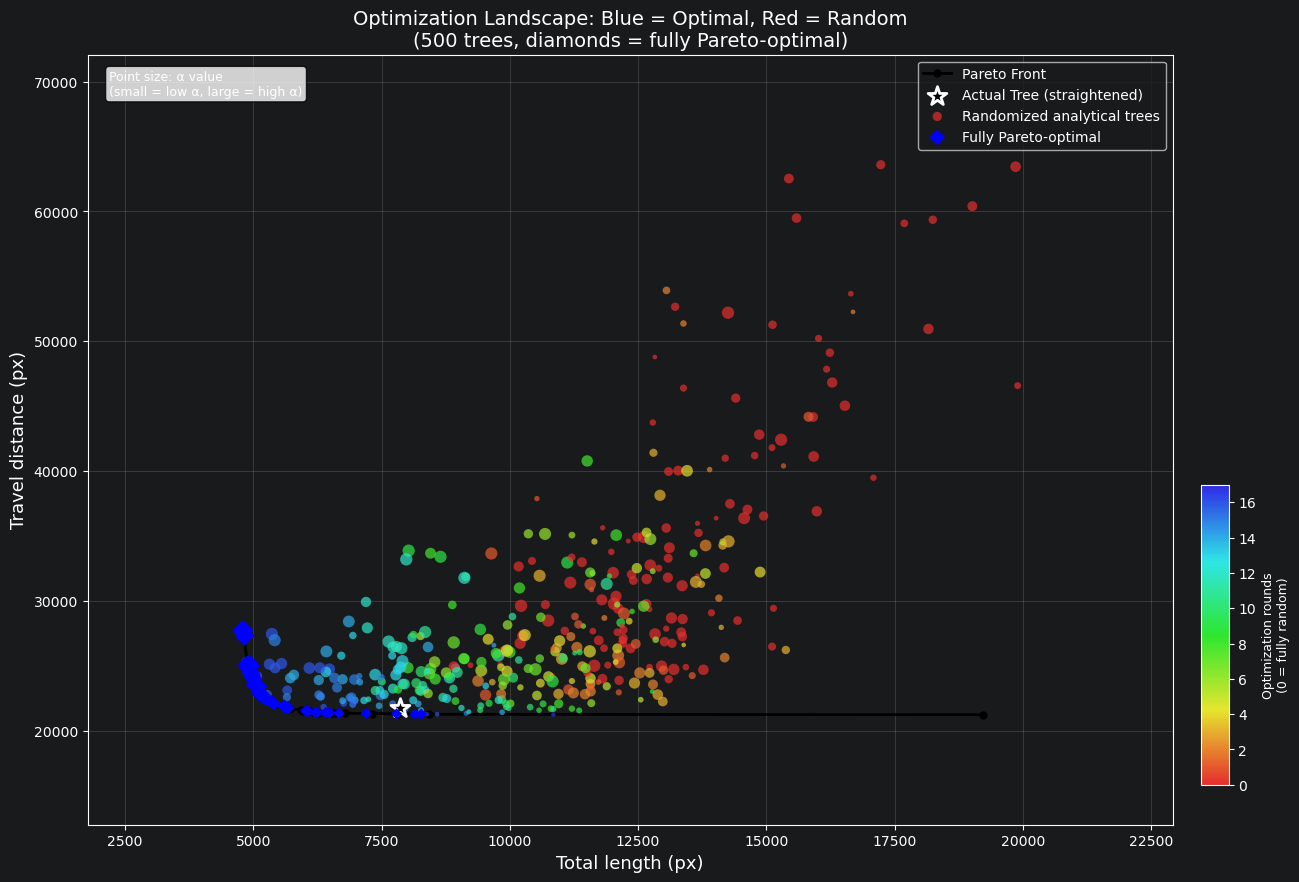

(<Figure size 1400x1000 with 2 Axes>,
 <Axes: title={'center': 'Optimization Landscape: Blue = Optimal, Red = Random\n(500 trees, diamonds = fully Pareto-optimal)'}, xlabel='Total length (px)', ylabel='Travel distance (px)'>)

In [8]:
plot_randomization_landscape(H, n_trees=N_LANDSCAPE, dest=None)

## 5. Optimization level of the real RSA

Sample semi-random analytical architectures around the actual tree, retain the
ones inside the elliptical target region, and estimate the weighted mean
optimization level and trade-off direction alpha.

For each retained architecture, we record both its optimization level and the $\alpha$ value used to generate it. To avoid over-representing samples that happen to fall near the boundary of the ellipse, we weight each point by its proximity to the actual tree: a weight of one at the center, decreasing linearly to zero at the boundary. We then compute weighted means and confidence intervals for both quantities, using the effective sample size (Kish's formula) to account for the reduction in information introduced by the weighting. The resulting statistics provide a probabilistic classification of the actual root system: the mean optimization level estimates the amount of greedy construction needed to reach architectures as efficient as the real plant, and the mean $\alpha$ estimates the trade-off direction that best characterizes its location in the Pareto plane. The figure below illustrates the procedure on a representative root system: the sampled architectures are colored by optimization level and sized by $\alpha$, with the red dashed ellipse marking the target region around the actual tree. The black horizontal bar on the colorbar indicates the weighted mean optimization level of the samples inside the region.

Actual tree: wiring=7856.2, travel=21751.4
Scaling distance to front: 1.0202
Ellipse radii: (116.4555, 322.4312)
Max rounds: 17
Generating 5000 semi-random trees...
  500/5000, inside: 0
  1000/5000, inside: 0
  1500/5000, inside: 1
  2000/5000, inside: 2
  2500/5000, inside: 3
  3000/5000, inside: 3
  3500/5000, inside: 3
  4000/5000, inside: 3
  4500/5000, inside: 3
  5000/5000, inside: 5

Total inside region: 5

Weighted results (n_inside=5, n_eff=3.7):
  Mean rounds: 13.75 (normalized: 0.809)
  95% CI: [12.99, 14.52] (normalized: [0.764, 0.854])
  Mean alpha: 0.148
  95% CI: [0.073, 0.223]


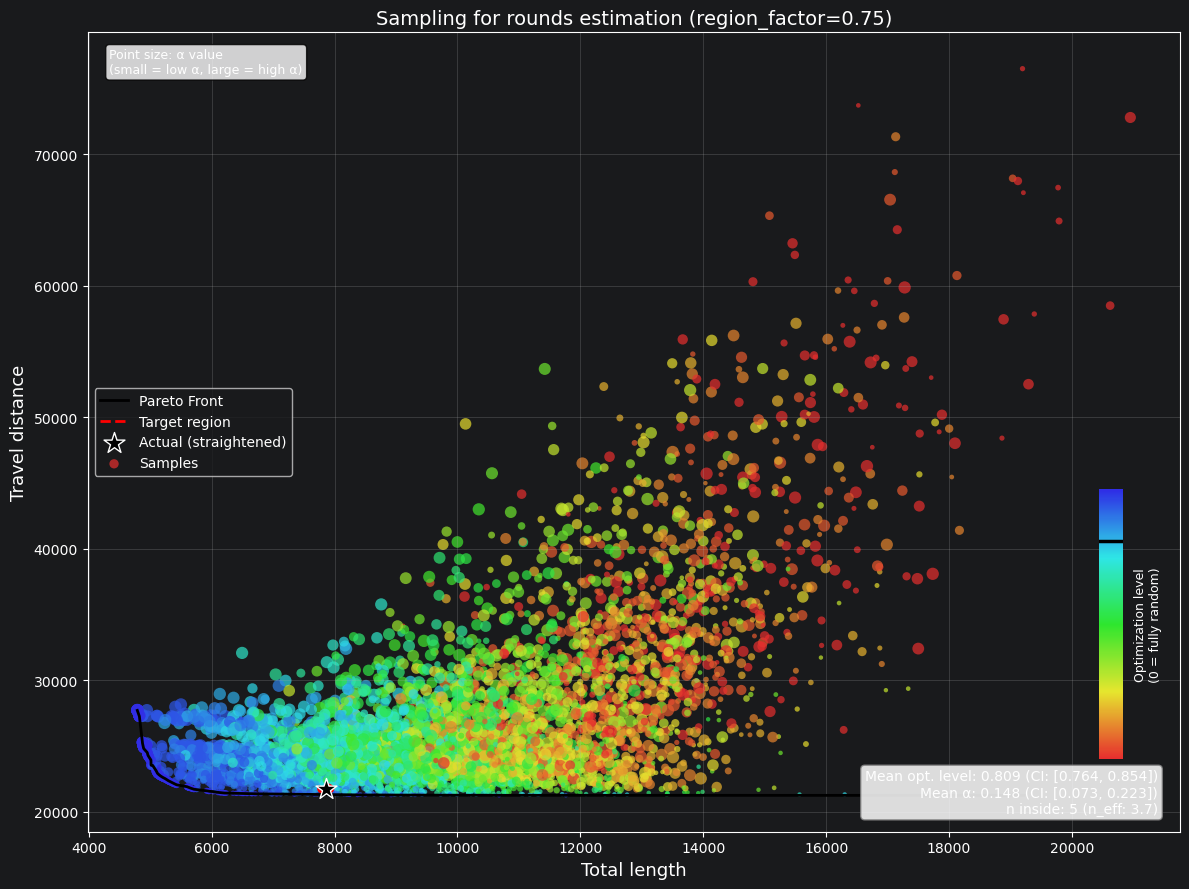

Weighted results
  mean optimization level: 0.8090651896416488 (CI: 0.7640157164550996, 0.8541146628281978)
  mean alpha: 0.14829720259724508 (CI: 0.07343580684134479, 0.22315859835314536)
  n inside: 5


In [9]:
front, actual = pareto_front(H)

sampling = estimate_rounds_for_region(
    H,
    n_samples=N_SAMPLES,
    region_factor=REGION_FACTOR,
    plot=True,
    show=True,
    front=front,
    actual=actual,
    verbose=True,
)

print("Weighted results")
print(
    "  mean optimization level:",
    sampling["mean_rounds_normalized"],
    f"(CI: {sampling['ci_low_normalized']}, {sampling['ci_high_normalized']})",
)
print(
    "  mean alpha:",
    sampling["mean_alpha"],
    f"(CI: {sampling['alpha_ci_low']}, {sampling['alpha_ci_high']})",
)
print("  n inside:", sampling["n_inside"])

## Notes

- `N_MST`, `N_TOPDOWN`, `N_BOTTOMUP`, `N_ANALYTICAL`, `N_LANDSCAPE`, and
  `N_SAMPLES` control the runtime.
- The values used for the figures are 500, 200, 300, 500, 500, and 5000.
- All computations are performed before their plots, so individual cells can be
  rerun without rebuilding the rest of the notebook.